# Milestone 2 - Data Cleaning and Preparation
All cleaning logic lives in `src/clean.py` so it is tested once and reused by every notebook, the SQL load and the
dashboard. This notebook walks through **each problem, the evidence for it, the decision taken and why**.

Principles:
1. **Never silently change data** - every step is logged (rows before/after) in `data/processed/cleaning_log.csv`.
2. **Fix when the correct value is recoverable** (labels, date formats, prices from the price list); **drop when it is not**
   (keying-error quantities, test receipts) - and only if the dropped volume is immaterial.
3. **Keep legitimate oddities**: returns (negative quantities) and walk-in shoppers (no customer id) are real business events.

In [1]:
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import clean
from config import RAW, PROCESSED, set_style, PALETTE
set_style()

raw_tx = pd.read_csv(RAW / "transactions.csv", dtype={"customer_id": str})
raw_items = pd.read_csv(RAW / "transaction_items.csv", dtype={"promo_id": str})
raw_cust = pd.read_csv(RAW / "customers.csv")
raw_stores = pd.read_csv(RAW / "stores.csv")
raw_prod = pd.read_csv(RAW / "products.csv")
print(raw_tx.dtypes, "\n")
print(raw_items.dtypes)

transaction_id            str
transaction_datetime      str
store_id                  str
till_no                 int64
customer_id               str
payment_method            str
total_amount              str
dtype: object 

transaction_id         str
line_no              int64
product_id             str
quantity             int64
unit_price         float64
discount_amount    float64
promo_id               str
dtype: object


## 1. Types
`transaction_datetime` and `total_amount` load as text (`object`). The amount column mixes numbers with `"KES 1,234.00"`
strings, and dates come in two formats.

In [2]:
print("Non-numeric total_amount examples:",
      raw_tx.total_amount[pd.to_numeric(raw_tx.total_amount, errors="coerce").isna() & raw_tx.total_amount.notna()].head(3).tolist())
print("Non-ISO datetime examples:",
      raw_tx.transaction_datetime[~raw_tx.transaction_datetime.str.match(r"\d{4}-")].head(3).tolist())

Non-numeric total_amount examples: ['KES 470.00', 'KES 70.00', 'KES 800.00']
Non-ISO datetime examples: ['21/12/2025 08:07', '06/07/2026 18:56', '06/06/2026 16:06']


**Decision:** parse `dd/mm/YYYY HH:MM` explicitly (day-first - Kenyan convention) rather than letting pandas guess,
which would read 03/04 as 4 March. Strip `KES` and thousands separators from amounts.

## 2. Missing values

In [3]:
miss = pd.concat({
    "transactions": raw_tx.isna().mean(), "items": raw_items.isna().mean(),
    "customers": raw_cust.isna().mean()}).mul(100).round(2)
miss[miss > 0].to_frame("% missing")

% missing
transactions customer_id         49.91
             payment_method       0.80
             total_amount         0.40
items        unit_price           0.60
             promo_id            97.08
customers    gender               3.00

| Column | Why it is missing | Treatment |
|---|---|---|
| `customer_id` (~50%) | Walk-in shoppers without a loyalty card - **not an error** | Keep; flag `is_member` |
| `payment_method` (~0.8%) | Till did not capture it | Label `Unknown` (dropping would lose real sales) |
| `total_amount` (~0.4%) | Export glitch | Recompute from lines - the reliable source |
| `unit_price` (~0.6%) | Export glitch | Median price of same product, same store, same month (prices are set monthly) |
| `promo_id` (most rows) | Line not on promotion - **structural** | Keep as null; flag `on_promo` |
| `gender`, `birth_year` | Not captured at sign-up | `Unknown` category; impossible years set to missing |

## 3. Duplicates

In [4]:
print("exact duplicate receipts :", raw_tx.duplicated().sum())
print("exact duplicate lines    :", raw_items.duplicated().sum())
print("duplicate customer rows  :", raw_cust.duplicated().sum())
print("test receipts (S999)     :", (raw_tx.store_id == "S999").sum())

exact duplicate receipts : 1313
exact duplicate lines    : 1925
duplicate customer rows  : 30
test receipts (S999)     : 25


## 4. Outliers
Two very different kinds of "outlier":
* **Errors** - a quantity of 999 cooking-oil bottles in one household basket is a keying error (wrong field on the till).
* **Genuine extremes** - a KES 15,000 festive basket is unusual but real, and must be kept.

0.500    1.0
0.900    2.0
0.990    5.0
0.999    6.0
Name: quantity, dtype: float64


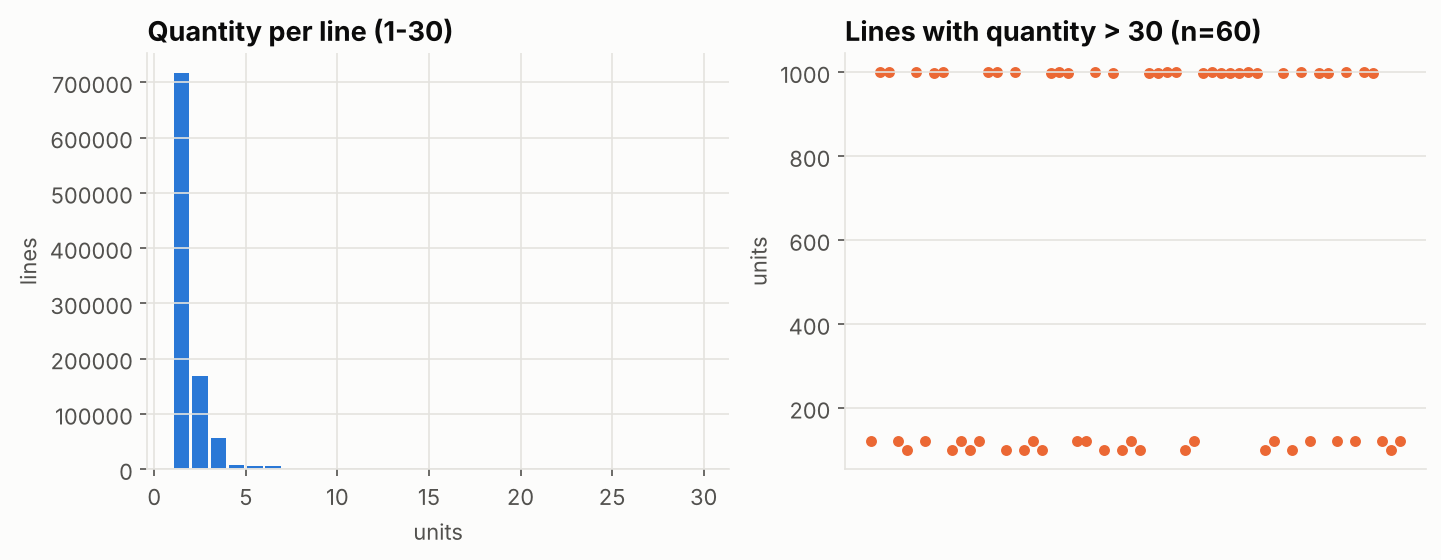

In [5]:
q = raw_items.quantity
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(q[(q > 0) & (q <= 30)], bins=range(1, 31), color=PALETTE[0], rwidth=0.85)
ax[0].set(title="Quantity per line (1-30)", xlabel="units", ylabel="lines")
ax[1].scatter(np.arange((q > 30).sum()), q[q > 30], color=PALETTE[1], s=18)
ax[1].set(title=f"Lines with quantity > 30 (n={(q > 30).sum()})", ylabel="units", xticks=[])
print(q[q > 0].quantile([.5, .9, .99, .999]))

**Decision:** the 99th percentile is 5 units and the 99.9th is under 10, while the suspicious values cluster at 99, 120, 999
and 1000 - classic keying errors. Rule: drop lines with |quantity| > 30 (60 lines, 0.006% of lines). We *drop* rather than
cap because the true quantity is unknowable; capping would invent data.

## 5. Inconsistent categories

In [6]:
print(raw_stores.county.tolist())
print("\nproducts with missing category:\n", raw_prod[raw_prod.category.isna()][["product_id", "product_name", "subcategory"]])

['Nairobi', 'Nairobi', 'NAIROBI', ' Nairobi', 'Nairobi', 'Nairobi', 'Mombasa', 'Mombasa', 'Kiambu', 'Kiambu', 'Nakuru', ' Nakuru', 'Kisumu', 'Kisumu', ' Uasin Gishu', 'Machakos', 'Kakamega', 'nyeri', 'Kilifi', 'Kajiado']

products with missing category:
    product_id              product_name   subcategory
23      P0024            Mangoes per kg         Fruit
33      P0034  Strawberry Yoghurt 500ml       Yoghurt
37      P0038     Kenya Tea Leaves 500g  Tea & Coffee
79      P0080        HB Pencils 12 Pack       Writing


## 6. Run the full, logged pipeline

In [7]:
sales = clean.main()

           table                                                           step  rows_before  rows_after  rows_affected                                note
0         stores                     standardise county names (case/whitespace)           20          20            NaN                      5 values fixed
1       products                       impute missing category from subcategory           91          91            NaN                            4 filled
2      customers                                    drop duplicate sign-up rows         6030        6000           30.0                                    
3      customers                              standardise gender to F/M/Unknown         6000        6000            NaN                         180 unknown
4      customers         set impossible birth years (<1930 or >2008) to missing         6000        6000            NaN                           60 values
5   transactions                                      drop exact

In [8]:
log = pd.read_csv(PROCESSED / "cleaning_log.csv")
log

,table,step,rows_before,rows_after,rows_affected,note
0,stores,standardise county names (case/whitespace),20,20,NaN,5 values fixed
1,products,impute missing category from subcategory,91,91,NaN,4 filled
2,customers,drop duplicate sign-up rows,6030,6000,30.0,NaN
3,customers,standardise gender to F/M/Unknown,6000,6000,NaN,180 unknown
4,customers,set impossible birth years (<1930 or >2008) to missing,6000,6000,NaN,60 values
5,transactions,drop exact duplicate rows,329599,328286,1313.0,NaN
6,transactions,remove POS test transactions (unknown store S999 / TEST ids),328286,328261,25.0,NaN
7,transactions,parse mixed datetime formats (dd/mm/YYYY rows),328261,328261,NaN,6565 non-ISO rows parsed day-first
8,transactions,"drop rows with impossible dates (POS clock errors, year 2031)",328261,328249,12.0,NaN
9,transactions,drop repeated transaction_id (same receipt keyed twice),328249,328249,NaN,NaN


## 7. Validation after cleaning
Checks that must all pass before any analysis:

In [9]:
tx = pd.read_pickle(PROCESSED / "transactions.pkl")
checks = {
    "no duplicate transaction_id": tx.transaction_id.is_unique,
    "all dates inside Oct-2024..Sep-2026": tx.transaction_datetime.between("2024-10-01", "2026-10-01").all(),
    "all stores known": tx.store_id.isin(pd.read_csv(PROCESSED / "stores.csv").store_id).all(),
    "payment methods in 5 clean labels": set(tx.payment_method) <= {"M-Pesa", "Cash", "Card", "Airtel Money", "Unknown"},
    "no missing unit price": sales.unit_price.notna().all(),
    "every line has a category": sales.category.notna().all(),
    "till totals reconcile with lines (>99.9%)": (~tx.total_mismatch).mean() > 0.999,
    "revenue from lines == revenue from receipts": np.isclose(sales.net_amount.sum(), tx.net_amount.sum()),
}
pd.Series(checks, name="passed").to_frame()

,passed
no duplicate transaction_id,True
all dates inside Oct-2024..Sep-2026,True
all stores known,True
payment methods in 5 clean labels,True
no missing unit price,True
every line has a category,True
till totals reconcile with lines (>99.9%),True
revenue from lines == revenue from receipts,True


## 8. Features engineered
| Feature | Definition | Used for |
|---|---|---|
| `gross_amount`, `net_amount` | qty x price; less promo discount | revenue |
| `is_return` | quantity < 0 | returns analysis, net sales |
| `is_weekend`, `day_of_week`, `hour` | from timestamp | seasonality, staffing |
| `is_payday_window` | day >= 25 or <= 3 (salaries paid month-end in Kenya) | payday effect |
| `is_public_holiday` | joined from the gazetted holiday file | demand forecasting |
| `inflation_12m_pct`, `cpi_index` | joined by month from KNBS/CBK | context |
| `net_amount_real` | revenue deflated to Oct-2024 shillings using the CPI index | real growth (Q7) |
| `age`, `age_band`, `tenure` | from customer master | segmentation, churn |
| `n_lines`, `units`, `has_promo` | per receipt | basket analysis |

In [10]:
sales.head()

,transaction_id,line_no,product_id,quantity,unit_price,discount_amount,promo_id,is_return,gross_amount,net_amount,...,month_num,day_of_week,hour,is_weekend,is_payday_window,is_public_holiday,on_promo,inflation_12m_pct,cpi_index,net_amount_real
0,T0000001,1,P0005,1,395.0,0.0,NaN,False,395.0,395.0,...,10,Tuesday,18,False,True,False,False,2.72,100.0,395.0
1,T0000001,2,P0016,1,94.0,0.0,NaN,False,94.0,94.0,...,10,Tuesday,18,False,True,False,False,2.72,100.0,94.0
2,T0000001,3,P0028,1,450.0,0.0,NaN,False,450.0,450.0,...,10,Tuesday,18,False,True,False,False,2.72,100.0,450.0
3,T0000001,4,P0034,1,140.0,0.0,NaN,False,140.0,140.0,...,10,Tuesday,18,False,True,False,False,2.72,100.0,140.0
4,T0000001,5,P0044,1,78.0,0.0,NaN,False,78.0,78.0,...,10,Tuesday,18,False,True,False,False,2.72,100.0,78.0


In [11]:
print(f"Clean fact table: {len(sales):,} lines | {sales.transaction_id.nunique():,} receipts | "
      f"net revenue KES {sales.net_amount.sum()/1e6:,.1f}M | returns {sales.is_return.mean():.2%} of lines")

Clean fact table: 962,218 lines | 328,244 receipts | net revenue KES 296.2M | returns 0.30% of lines
